**Retail Sales Analysis Using Python**

Customer Behavior, Product Performance & Sales Trend Analysis.

**Main Objective of Project:-**

The objective of this project is to analyze retail sales data
and identify customer purchasing behavior, product performance,
sales trends, seasonal patterns, quantity preferences and
product pricing patterns using Python.

In [ ]:
import pandas as pd
import numpy as np

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

**Importing the Dataset**

In [31]:
df = pd.read_csv("/content/Retail Sales .csv")

In [32]:
df.head()

,transactions_id,sale_date,sale_time,customer_id,gender,age,category,quantiy,price_per_unit,cogs,total_sale
0,180,2022-11-05,10:47:00,117,Male,41.0,Clothing,3.0,300.0,129.0,900.0
1,522,2022-07-09,11:00:00,52,Male,46.0,Beauty,3.0,500.0,145.0,1500.0
2,559,2022-12-12,10:48:00,5,Female,40.0,Clothing,4.0,300.0,84.0,1200.0
3,1180,2022-01-06,08:53:00,85,Male,41.0,Clothing,3.0,300.0,129.0,900.0
4,1522,2022-11-14,08:35:00,48,Male,46.0,Beauty,3.0,500.0,235.0,1500.0


In [33]:
df.tail()

,transactions_id,sale_date,sale_time,customer_id,gender,age,category,quantiy,price_per_unit,cogs,total_sale
1995,1857,2022-11-09,12:15:00,109,Male,60.0,Electronics,2.0,25.0,7.5,50.0
1996,211,2022-09-12,14:02:00,54,Male,42.0,Beauty,3.0,500.0,235.0,1500.0
1997,650,2023-10-08,12:41:00,98,Male,55.0,Electronics,1.0,30.0,15.0,30.0
1998,1211,2023-11-22,14:59:00,82,Male,42.0,Beauty,3.0,500.0,235.0,1500.0
1999,1650,2022-09-23,16:24:00,89,Male,55.0,Electronics,1.0,30.0,10.8,30.0


**Understanding the Dataset**

In [34]:
df.shape

(2000, 11)

In [35]:
df.columns

Index(['transactions_id', 'sale_date', 'sale_time', 'customer_id', 'gender',
       'age', 'category', 'quantiy', 'price_per_unit', 'cogs', 'total_sale'],
      dtype='object')

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   transactions_id  2000 non-null   int64  
 1   sale_date        2000 non-null   object 
 2   sale_time        2000 non-null   object 
 3   customer_id      2000 non-null   int64  
 4   gender           2000 non-null   object 
 5   age              1990 non-null   float64
 6   category         2000 non-null   object 
 7   quantiy          1997 non-null   float64
 8   price_per_unit   1997 non-null   float64
 9   cogs             1997 non-null   float64
 10  total_sale       1997 non-null   float64
dtypes: float64(5), int64(2), object(4)
memory usage: 172.0+ KB


In [37]:
df.describe()

,transactions_id,customer_id,age,quantiy,price_per_unit,cogs,total_sale
count,2000.000000,2000.000000,1990.000000,1997.000000,1997.000000,1997.000000,1997.000000
mean,1000.500000,66.341500,41.343216,2.512769,180.117677,95.023886,456.544817
std,577.494589,44.937185,13.668167,1.132708,189.685225,121.898695,560.101381
min,1.000000,1.000000,18.000000,1.000000,25.000000,6.250000,25.000000
25%,500.750000,24.000000,29.000000,1.000000,30.000000,13.000000,60.000000
50%,1000.500000,69.000000,42.000000,3.000000,50.000000,27.500000,150.000000
75%,1500.250000,102.000000,53.000000,4.000000,300.000000,147.000000,900.000000
max,2000.000000,155.000000,64.000000,4.000000,500.000000,620.000000,2000.000000


In [38]:
df.isnull().sum()

,0
transactions_id,0
sale_date,0
sale_time,0
customer_id,0
gender,0
age,10
category,0
quantiy,3
price_per_unit,3
cogs,3


In [39]:
df.duplicated().sum()

np.int64(0)

**Data Cleaning**

In [50]:
df.rename(columns={"quantiy":"quantity"}, inplace=True)

In [51]:
df.columns

Index(['transactions_id', 'sale_date', 'sale_time', 'customer_id', 'gender',
       'age', 'category', 'quantity', 'price_per_unit', 'cogs', 'total_sale'],
      dtype='object')

**Convert Sale Date**

In [52]:
df["sale_date"] = pd.to_datetime(df["sale_date"])

In [53]:
df["sale_date"].head()

,sale_date
0,2022-11-05
1,2022-07-09
2,2022-12-12
3,2022-01-06
4,2022-11-14


**Checking Missing Rows**

In [54]:
df[df.isnull().any(axis=1)]

,transactions_id,sale_date,sale_time,customer_id,gender,age,category,quantity,price_per_unit,cogs,total_sale
24,432,2022-03-10,11:31:00,17,Female,NaN,Electronics,2.0,500.0,190.00,1000.0
25,1367,2022-04-15,11:38:00,16,Female,NaN,Electronics,1.0,50.0,15.50,50.0
26,1391,2022-03-01,11:29:00,130,Male,NaN,Beauty,2.0,25.0,9.25,50.0
27,1432,2022-12-25,06:24:00,67,Female,NaN,Electronics,2.0,500.0,245.00,1000.0
28,150,2022-04-13,08:25:00,89,Female,NaN,Electronics,4.0,30.0,16.20,120.0
29,845,2022-10-27,10:12:00,25,Male,NaN,Clothing,1.0,500.0,145.00,500.0
30,1150,2022-08-22,10:04:00,77,Female,NaN,Electronics,4.0,30.0,10.20,120.0
31,1845,2022-05-24,07:06:00,94,Male,NaN,Clothing,1.0,500.0,185.00,500.0
32,797,2022-09-16,06:38:00,116,Male,NaN,Clothing,3.0,25.0,10.75,75.0
33,921,2022-09-28,09:34:00,101,Male,NaN,Electronics,3.0,25.0,8.00,75.0


In [55]:
df = df.dropna()

In [56]:
df.isnull().sum()

,0
transactions_id,0
sale_date,0
sale_time,0
customer_id,0
gender,0
age,0
category,0
quantity,0
price_per_unit,0
cogs,0


In [57]:
df["year"] = df["sale_date"].dt.year

/tmp/ipykernel_5024/4244355579.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["year"] = df["sale_date"].dt.year


In [58]:
df["month"] = df["sale_date"].dt.month

/tmp/ipykernel_5024/998991069.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["month"] = df["sale_date"].dt.month


In [59]:
df.head()

,transactions_id,sale_date,sale_time,customer_id,gender,age,category,quantity,price_per_unit,cogs,total_sale,year,month
0,180,2022-11-05,10:47:00,117,Male,41.0,Clothing,3.0,300.0,129.0,900.0,2022,11
1,522,2022-07-09,11:00:00,52,Male,46.0,Beauty,3.0,500.0,145.0,1500.0,2022,7
2,559,2022-12-12,10:48:00,5,Female,40.0,Clothing,4.0,300.0,84.0,1200.0,2022,12
3,1180,2022-01-06,08:53:00,85,Male,41.0,Clothing,3.0,300.0,129.0,900.0,2022,1
4,1522,2022-11-14,08:35:00,48,Male,46.0,Beauty,3.0,500.0,235.0,1500.0,2022,11


**Data Visualization**

In [60]:
df["customer_id"].nunique()

155

**Gender Analysis**

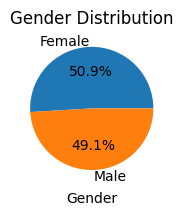

In [63]:
gender_count = df["gender"].value_counts()

marks = gender_count.values
names = gender_count.index
plt.figure(figsize=(4,2))
plt.pie(marks, labels=names, autopct="%1.1f%%")
plt.xlabel("Gender")
plt.title("Gender Distribution")
plt.show()

**Gender VS TotalSales**

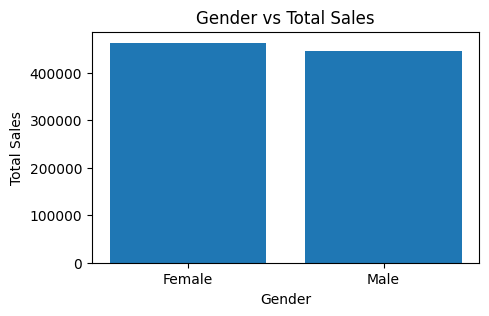

In [64]:
gender_sales = df.groupby("gender")["total_sale"].sum()
plt.figure(figsize=(5,3))
plt.bar(gender_sales.index, gender_sales.values)
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.title("Gender vs Total Sales")
plt.show()

**Age Analysis**

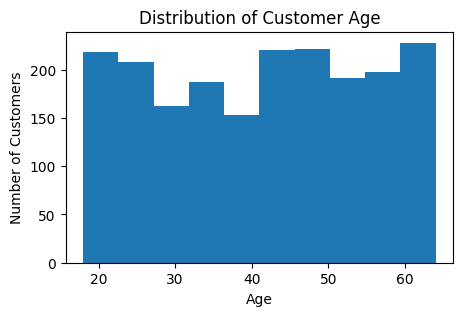

In [65]:
plt.figure(figsize=(5,3))
plt.hist(df["age"].dropna())
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Age")
plt.show()

**Age vs Average Total Sale**

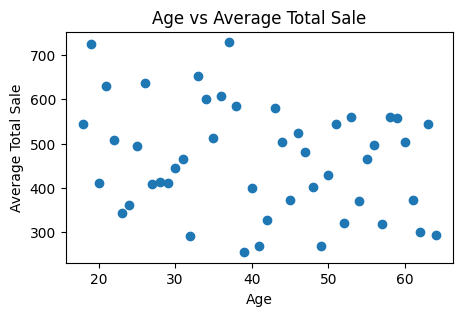

In [66]:
age_sales = df.groupby("age")["total_sale"].mean()
plt.figure(figsize=(5,3))
plt.plot(
    age_sales.index,
    age_sales.values,
    marker="o",
    linestyle=""
)
plt.xlabel("Age")
plt.ylabel("Average Total Sale")
plt.title("Age vs Average Total Sale")
plt.show()

**PRODUCT CATEGORY ANALYSIS**

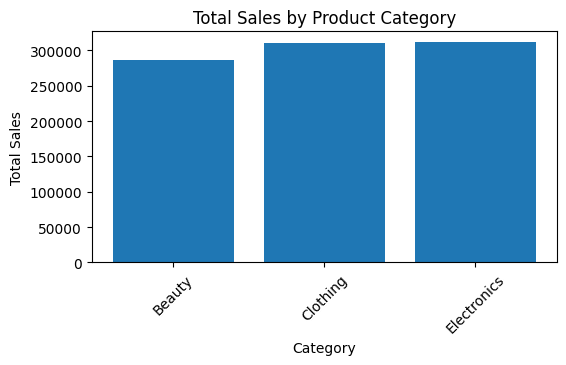

In [67]:
category_sales = df.groupby("category")["total_sale"].sum()
plt.figure(figsize=(6,3))
plt.bar(category_sales.index, category_sales.values)
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.title("Total Sales by Product Category")
plt.xticks(rotation=45)
plt.show()

**TIME ANALYSIS**

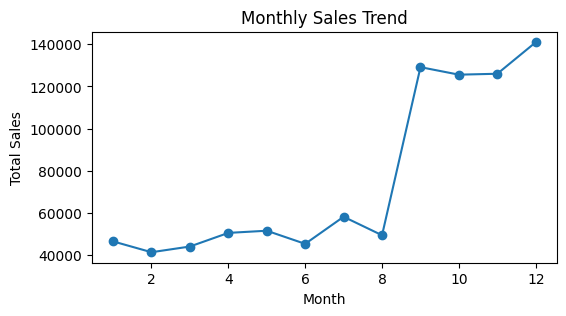

In [68]:
monthly_sales = df.groupby("month")["total_sale"].sum()
plt.figure(figsize=(6,3))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")
plt.show()

**Year vs Total Sales**

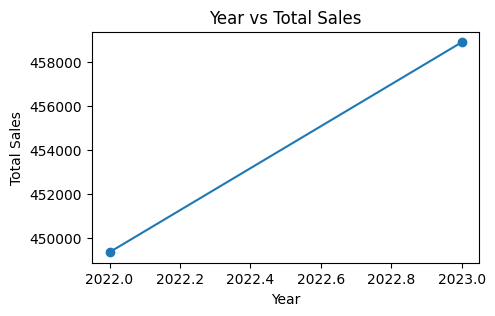

In [69]:
year_sales = df.groupby("year")["total_sale"].sum()
plt.figure(figsize=(5,3))
plt.plot(
    year_sales.index,
    year_sales.values,
    marker="o"
)
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.title("Year vs Total Sales")
plt.show()

**Seasonal Analysis:-**

In [70]:
df["season"] = df["month"].map({
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
})

/tmp/ipykernel_5024/2960884303.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["season"] = df["month"].map({


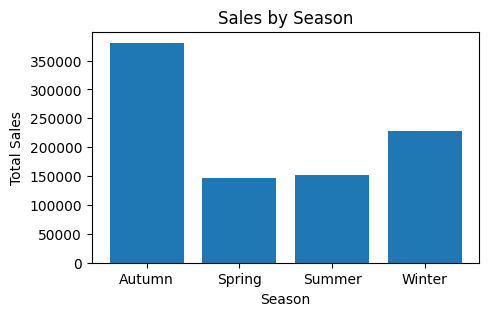

In [71]:
season_sales = df.groupby("season")["total_sale"].sum()
plt.figure(figsize=(5,3))
plt.bar(season_sales.index, season_sales.values)
plt.xlabel("Season")
plt.ylabel("Total Sales")
plt.title("Sales by Season")
plt.show()

**Quantity vs Average Total Sale**

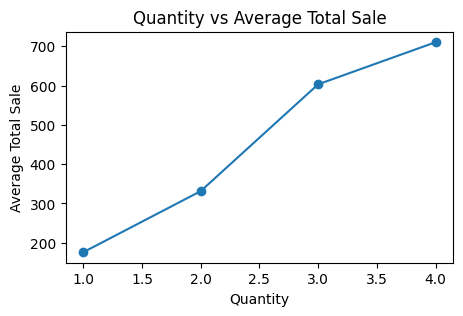

In [72]:
quantity_sales = df.groupby("quantity")["total_sale"].mean()
plt.figure(figsize=(5,3))
plt.plot(
    quantity_sales.index,
    quantity_sales.values,
    marker="o"
)
plt.xlabel("Quantity")
plt.ylabel("Average Total Sale")
plt.title("Quantity vs Average Total Sale")
plt.show()

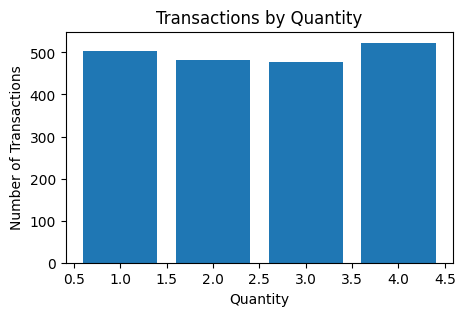

In [73]:
quantity_count = df["quantity"].value_counts().sort_index()
plt.figure(figsize=(5,3))
plt.bar(quantity_count.index, quantity_count.values)
plt.xlabel("Quantity")
plt.ylabel("Number of Transactions")
plt.title("Transactions by Quantity")
plt.show()

**Price Analysis**

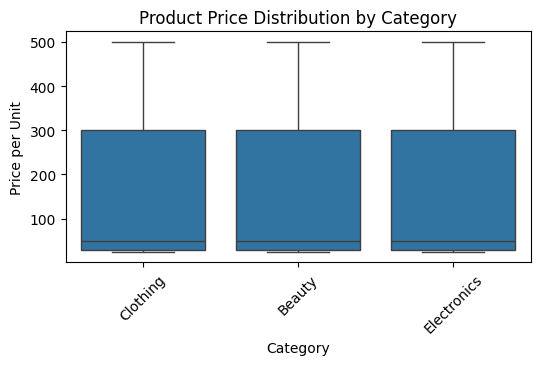

In [74]:
plt.figure(figsize=(6,3))
sns.boxplot(
    data=df,
    x="category",
    y="price_per_unit"
)
plt.xlabel("Category")
plt.ylabel("Price per Unit")
plt.title("Product Price Distribution by Category")
plt.xticks(rotation=45)
plt.show()

**Age and Product Difference**

In [75]:
age_category = df.groupby(
    ["age", "category"]
)["total_sale"].sum().reset_index()

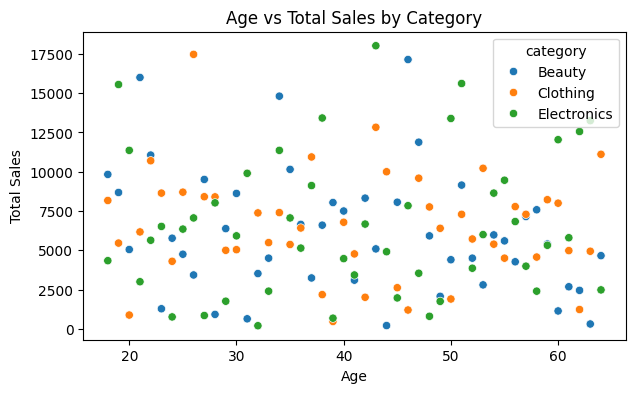

In [76]:
plt.figure(figsize=(7,4))
sns.scatterplot(
    data=age_category,
    x="age",
    y="total_sale",
    hue="category"
)
plt.xlabel("Age")
plt.ylabel("Total Sales")
plt.title("Age vs Total Sales by Category")
plt.show()

**OBSERVATION:-**

This analysis compares customer age, total spending, and product category.

The visualization helps identify whether different age groups show different
spending patterns across product categories. It can also help identify
categories that appear more frequently among particular age groups.

**BUSINESS Q&A'S:-**

### 1. How does customer age and gender influence purchasing behavior?

Gender analysis shows that the customer base is relatively balanced between
male and female customers. Age analysis also shows that spending varies
across different age groups.

However, the analysis shows relationships and patterns rather than proving
that age or gender directly causes differences in spending.

### 2. Are there discernible patterns in sales across different time periods?

Yes. Monthly and yearly analysis shows that sales vary across different
time periods. Some months and years perform better than others.

These patterns can help businesses plan inventory, promotions, and marketing
activities.

### 3. Which product categories hold the highest appeal among customers?

Category-wise sales analysis shows that some product categories generate
higher total sales than others.

The highest-performing category can be identified from the category sales
visualization and can be given greater attention in inventory and marketing
decisions.

### 4. What are the relationships between age, spending, and product preferences?

The age and category analysis shows differences in spending across age groups
and product categories.

This can help identify potential customer segments and their product
preferences.

### 5. How do customers adapt their shopping habits during seasonal trends?

Seasonal analysis shows that total sales differ across seasons.

This indicates that customer purchasing activity can change during different
times of the year, which can be useful for seasonal inventory and promotions.

### 6. Are there distinct purchasing behaviors based on the number of items
bought per transaction?

Yes. The quantity analysis shows that some transaction quantities occur more
frequently than others.

The relationship between quantity and average transaction value also helps
understand customer basket size.

### 7. What insights can be gleaned from the distribution of product prices
within each category?

Product price distributions differ across categories.

The box plot helps compare typical prices, price ranges, and possible
outliers between categories.

**KEY INSIGHTS:-**

- The customer base was relatively balanced between male and female customers.
- Customer spending varied across different age groups.
- Clothing generated the highest total sales among the analyzed product categories.
- Sales showed variation across different months and years.
- Sales performance differed across seasons.
- Certain transaction quantities were more common than others.
- Product prices varied across different categories.
- Age and product category analysis showed differences in purchasing patterns.

**BUSINESS RECOMMENDATIONS:-**

### 1. Focus on high-performing categories

Businesses can prioritize inventory and promotional activities for categories
that generate higher sales.

### 2. Use customer demographics

Age and gender patterns can be used to develop more targeted marketing
campaigns and customer segments.

### 3. Prepare for seasonal demand

Seasonal sales patterns can help businesses plan inventory and promotions
before periods of higher demand.

### 4. Encourage larger purchases

Businesses can experiment with bundle offers, quantity discounts, and
cross-selling strategies to encourage customers to purchase more items.

### 5. Review product pricing

The category-wise price distribution can help businesses compare pricing
patterns and identify products that may require further pricing analysis.

### 6. Use data for decision-making

Regular analysis of customer and sales data can help businesses improve
inventory planning, marketing strategies, pricing decisions, and overall
sales performance.

**CONCLUSION:-**

This project analyzed retail sales data to understand customer purchasing
behavior, product performance, sales trends, seasonal patterns, quantity
preferences, and product pricing.

Using Python, Pandas, Matplotlib, and Seaborn, the dataset was cleaned,
explored, and visualized to identify meaningful patterns in the sales data.

The analysis provided insights into customer demographics, spending behavior,
product categories, time-based sales performance, seasonal trends, transaction
quantities, and product price distributions.

Overall, this project helped demonstrate how data analysis can be used to
convert raw retail transaction data into meaningful business insights that
can support better decisions related to marketing, inventory, pricing, and
sales strategies.

This project also helped me strengthen my practical understanding of the
end-to-end data analysis process, from data cleaning and exploration to
visualization and business interpretation.